In [1]:

import os
import json
import time
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.kernel_approximation import Nystroem

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

metadata_files = [
    p for p in INPUT_DIR.rglob("metadata.json")
    if (p.parent / "X_train_scaled.npy").exists()
]

if not metadata_files:
    raise FileNotFoundError(
        "Processed dataset not found. "
        "Please add Notebook 00 output as input."
    )

DATA_DIR = metadata_files[0].parent

print("Dataset directory:", DATA_DIR)

print("\nAvailable files:")
for file in sorted(DATA_DIR.iterdir()):
    print(file.name)


Dataset directory: /kaggle/input/notebooks/ahmadlmomani/00-dry-bean-eda-preprocessing/dry_bean_processed

Available files:
X_test_scaled.csv
X_test_scaled.npy
X_train_scaled.csv
X_train_scaled.npy
imputer.pkl
label_encoder.pkl
metadata.json
scaler.pkl
y_test.csv
y_test.npy
y_train.csv
y_train.npy


In [3]:

X_train = np.load(DATA_DIR / "X_train_scaled.npy")
X_test = np.load(DATA_DIR / "X_test_scaled.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

class_names = metadata["classes"]
classes = np.unique(y_train)

print("Dataset loaded successfully!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("Classes:", class_names)
print("Number of Classes:", len(classes))


Dataset loaded successfully!
Training Features: (10834, 16)
Testing Features: (2709, 16)
Training Labels: (10834,)
Testing Labels: (2709,)
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Number of Classes: 7


In [4]:

KERNELS = {
    "Linear": {
        "kernel": "linear"
    },
    "Polynomial": {
        "kernel": "poly",
        "degree": 3,
        "coef0": 0
    },
    "RBF": {
        "kernel": "rbf"
    },
    "Sigmoid": {
        "kernel": "sigmoid",
        "coef0": 0
    }
}

RMSPROP_CONFIG = {
    "learning_rate": 0.001,
    "epochs": 100,
    "beta": 0.9,
    "epsilon": 1e-8,
    "regularization": 0.001,
    "n_components": 300
}

print("RMSProp Configuration:")
print(RMSPROP_CONFIG)

print("\nKernels:")
for name, params in KERNELS.items():
    print(name, params)


RMSProp Configuration:
{'learning_rate': 0.001, 'epochs': 100, 'beta': 0.9, 'epsilon': 1e-08, 'regularization': 0.001, 'n_components': 300}

Kernels:
Linear {'kernel': 'linear'}
Polynomial {'kernel': 'poly', 'degree': 3, 'coef0': 0}
RBF {'kernel': 'rbf'}
Sigmoid {'kernel': 'sigmoid', 'coef0': 0}


In [5]:

def train_svm_rmsprop(
    X,
    y,
    learning_rate=0.001,
    epochs=100,
    beta=0.9,
    epsilon=1e-8,
    reg_strength=0.001
):
    n_samples, n_features = X.shape

    classes = np.unique(y)
    n_classes = len(classes)

    # One-vs-Rest labels
    Y = np.where(
        y[:, None] == classes[None, :],
        1.0,
        -1.0
    )

    # Initialize weights
    W = np.zeros((n_features, n_classes))

    # Initialize squared gradient moving average
    cache = np.zeros_like(W)

    loss_history = []

    for epoch in range(epochs):

        # Calculate decision scores
        scores = X @ W

        # Calculate hinge margins
        margins = 1 - Y * scores

        # Identify active hinge losses
        active = (margins > 0).astype(float)

        # Calculate full-batch gradient
        gradient = (
            -(X.T @ (Y * active)) / n_samples
            + reg_strength * W
        )

        # Update squared gradient moving average
        cache = (
            beta * cache
            + (1 - beta) * (gradient ** 2)
        )

        # Adaptive RMSProp update
        W -= (
            learning_rate * gradient
            / (np.sqrt(cache) + epsilon)
        )

        # Calculate objective loss
        scores = X @ W

        margins = 1 - Y * scores

        hinge_loss = np.maximum(0, margins)

        epoch_loss = (
            np.mean(hinge_loss, axis=0).sum()
            + 0.5 * reg_strength * np.sum(W ** 2)
        )

        loss_history.append(epoch_loss)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"| Loss: {epoch_loss:.4f}"
            )

    return W, loss_history, classes


print("Multiclass SVM with RMSProp implemented successfully!")


Multiclass SVM with RMSProp implemented successfully!


In [6]:

rmsprop_models = {}
rmsprop_results = []

for kernel_name, kernel_params in KERNELS.items():

    print("\n" + "=" * 60)
    print(f"Training RMSProp with {kernel_name} Kernel")
    print("=" * 60)

    start_time = time.time()

    # Kernel approximation
    feature_map = Nystroem(
        n_components=RMSPROP_CONFIG["n_components"],
        random_state=RANDOM_STATE,
        gamma=1.0 / X_train.shape[1],
        **kernel_params
    )

    Z_train = feature_map.fit_transform(X_train)
    Z_test = feature_map.transform(X_test)

    # Train using RMSProp
    W, loss_history, trained_classes = train_svm_rmsprop(
        Z_train,
        y_train,
        learning_rate=RMSPROP_CONFIG["learning_rate"],
        epochs=RMSPROP_CONFIG["epochs"],
        beta=RMSPROP_CONFIG["beta"],
        epsilon=RMSPROP_CONFIG["epsilon"],
        reg_strength=RMSPROP_CONFIG["regularization"]
    )

    # Predictions
    test_scores = Z_test @ W

    y_pred = trained_classes[
        np.argmax(test_scores, axis=1)
    ]

    training_time = time.time() - start_time

    # Store trained model
    rmsprop_models[kernel_name] = {
        "feature_map": feature_map,
        "weights": W,
        "classes": trained_classes,
        "loss_history": loss_history
    }

    # Evaluation
    rmsprop_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Final Loss": loss_history[-1],
        "Training Time": training_time
    })

    print(f"\n{kernel_name} completed!")
    print(f"Final Loss: {loss_history[-1]:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll RMSProp experiments completed!")



Training RMSProp with Linear Kernel
Epoch 10/100 | Loss: 5.7995
Epoch 20/100 | Loss: 5.5433
Epoch 30/100 | Loss: 5.4319
Epoch 40/100 | Loss: 5.3515
Epoch 50/100 | Loss: 5.2755
Epoch 60/100 | Loss: 5.1970
Epoch 70/100 | Loss: 5.1160
Epoch 80/100 | Loss: 5.0347
Epoch 90/100 | Loss: 4.9544
Epoch 100/100 | Loss: 4.8764

Linear completed!
Final Loss: 4.8764
Training Time: 1.70 seconds

Training RMSProp with Polynomial Kernel
Epoch 10/100 | Loss: 6.5520
Epoch 20/100 | Loss: 6.3654
Epoch 30/100 | Loss: 6.2140
Epoch 40/100 | Loss: 6.0792
Epoch 50/100 | Loss: 5.9552
Epoch 60/100 | Loss: 5.8403
Epoch 70/100 | Loss: 5.7338
Epoch 80/100 | Loss: 5.6348
Epoch 90/100 | Loss: 5.5421
Epoch 100/100 | Loss: 5.4554

Polynomial completed!
Final Loss: 5.4554
Training Time: 1.91 seconds

Training RMSProp with RBF Kernel
Epoch 10/100 | Loss: 6.1270
Epoch 20/100 | Loss: 5.5614
Epoch 30/100 | Loss: 5.0392
Epoch 40/100 | Loss: 4.5300
Epoch 50/100 | Loss: 4.0252
Epoch 60/100 | Loss: 3.5220
Epoch 70/100 | Loss: 3

In [7]:

rmsprop_results_df = pd.DataFrame(rmsprop_results)

rmsprop_results_df = rmsprop_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("RMSProp Results")

display(
    rmsprop_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Final Loss": "{:.4f}",
        "Training Time": "{:.2f}"
    })
)


RMSProp Results


,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Final Loss,Training Time
0,Linear,0.8069,0.7801,0.8285,0.7901,0.8034,4.8764,1.70
1,RBF,0.7313,0.7752,0.7648,0.7264,0.6591,2.2242,1.69
2,Polynomial,0.7243,0.7711,0.7741,0.7104,0.6848,5.4554,1.91
3,Sigmoid,0.6667,0.8009,0.6815,0.6556,0.6131,4.9077,1.83


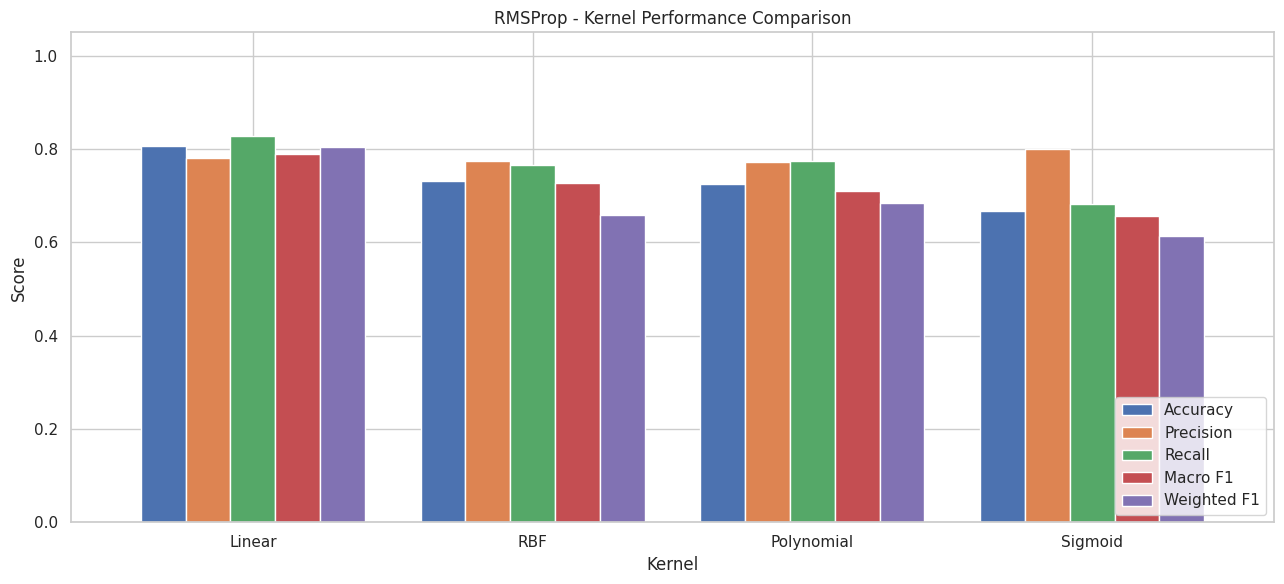

In [8]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1"
]

rmsprop_plot = rmsprop_results_df.set_index("Kernel")[metrics]

rmsprop_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("RMSProp - Kernel Performance Comparison")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


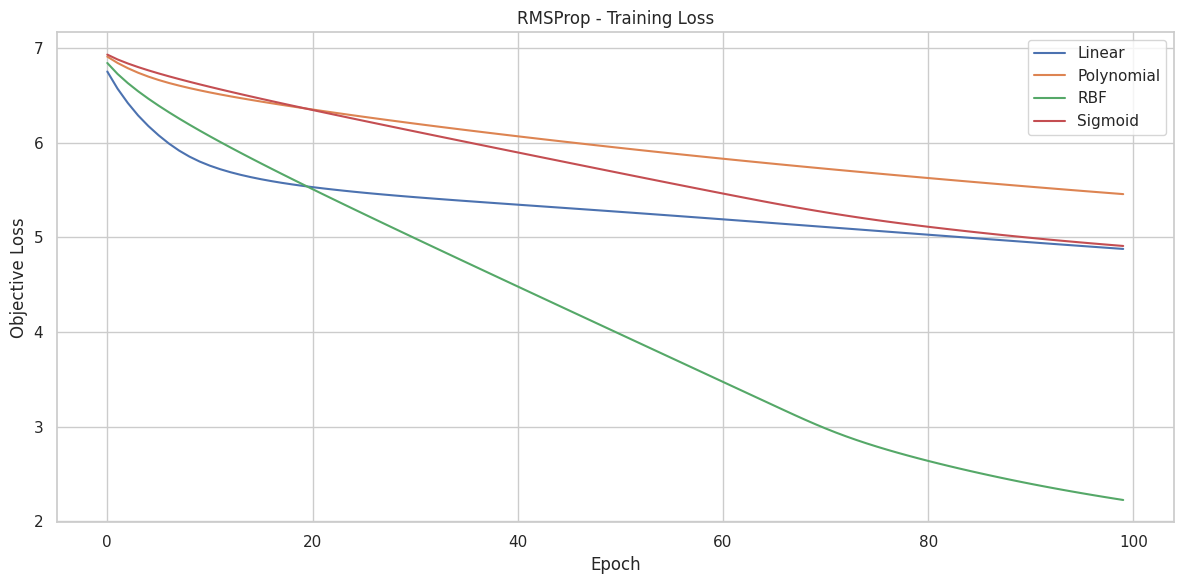

In [9]:

plt.figure(figsize=(12, 6))

for kernel_name, model_data in rmsprop_models.items():

    plt.plot(
        model_data["loss_history"],
        label=kernel_name
    )

plt.title("RMSProp - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Objective Loss")

plt.legend()
plt.tight_layout()
plt.show()


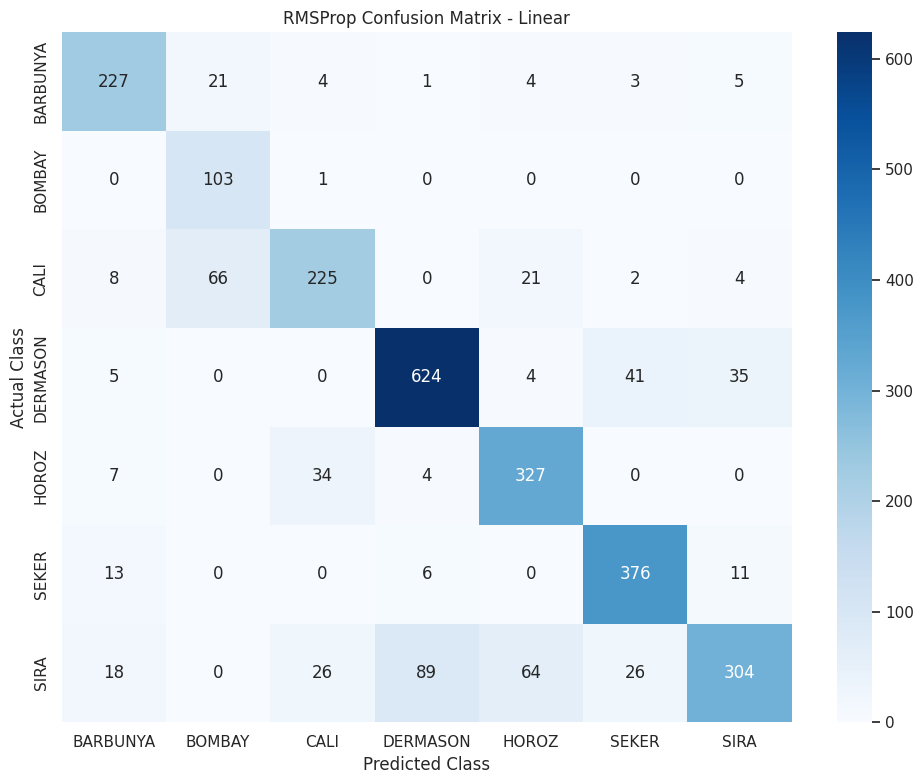

Best Kernel: Linear


In [10]:

best_kernel = rmsprop_results_df.iloc[0]["Kernel"]

best_model = rmsprop_models[best_kernel]

Z_test_best = best_model["feature_map"].transform(X_test)

y_pred = best_model["classes"][
    np.argmax(
        Z_test_best @ best_model["weights"],
        axis=1
    )
]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"RMSProp Confusion Matrix - {best_kernel}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Best Kernel:", best_kernel)


In [11]:

print(
    f"Classification Report - RMSProp with {best_kernel} Kernel"
)

print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        target_names=class_names,
        zero_division=0
    )
)


Classification Report - RMSProp with Linear Kernel
              precision    recall  f1-score   support

    BARBUNYA       0.82      0.86      0.84       265
      BOMBAY       0.54      0.99      0.70       104
        CALI       0.78      0.69      0.73       326
    DERMASON       0.86      0.88      0.87       709
       HOROZ       0.78      0.88      0.83       372
       SEKER       0.84      0.93      0.88       406
        SIRA       0.85      0.58      0.69       527

    accuracy                           0.81      2709
   macro avg       0.78      0.83      0.79      2709
weighted avg       0.82      0.81      0.80      2709



In [12]:

OUTPUT_DIR = Path("/kaggle/working/rmsprop_results")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison table
rmsprop_results_df.to_csv(
    OUTPUT_DIR / "rmsprop_comparison.csv",
    index=False
)

# Save models
joblib.dump(
    rmsprop_models,
    OUTPUT_DIR / "rmsprop_models.pkl"
)

# Save predictions for all kernels
predictions = {}

for kernel_name, model_data in rmsprop_models.items():

    Z_test = model_data["feature_map"].transform(X_test)

    scores = Z_test @ model_data["weights"]

    predictions[kernel_name] = model_data["classes"][
        np.argmax(scores, axis=1)
    ]

predictions_df = pd.DataFrame({
    "Actual": y_test
})

for kernel_name, pred in predictions.items():
    predictions_df[kernel_name] = pred

predictions_df.to_csv(
    OUTPUT_DIR / "rmsprop_predictions.csv",
    index=False
)

# Save configuration
config = {
    "optimizer": "RMSProp",
    "learning_rate": RMSPROP_CONFIG["learning_rate"],
    "epochs": RMSPROP_CONFIG["epochs"],
    "beta": RMSPROP_CONFIG["beta"],
    "epsilon": RMSPROP_CONFIG["epsilon"],
    "regularization": RMSPROP_CONFIG["regularization"],
    "n_components": RMSPROP_CONFIG["n_components"],
    "kernels": list(KERNELS.keys()),
    "random_state": RANDOM_STATE,
    "classes": class_names
}

with open(OUTPUT_DIR / "rmsprop_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("RMSProp results saved successfully!")

print("\nSaved files:")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


RMSProp results saved successfully!

Saved files:
rmsprop_predictions.csv
rmsprop_config.json
rmsprop_models.pkl
rmsprop_comparison.csv
